In [7]:
!unzip -o "/content/Online Retail.zip" -d "/content/online_retail_data"


unzip:  cannot find or open /content/Online Retail.zip, /content/Online Retail.zip.zip or /content/Online Retail.zip.ZIP.


In [8]:
import os
print(os.listdir("/content"))

['.config', 'online+retail.zip', 'sample_data']


In [9]:
!unzip -o "/content/online+retail.zip" -d "/content/online_retail_data"

Archive:  /content/online+retail.zip
 extracting: /content/online_retail_data/Online Retail.xlsx  


In [10]:
import os
print(os.listdir("/content/online_retail_data"))

['Online Retail.xlsx']


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/online_retail_data/Online Retail.xlsx"

df = pd.read_excel(file_path)

df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 541909
Number of Columns: 8


In [13]:
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [14]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [15]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Values Percentage:")
print(missing_percentage.round(2))

Missing Values Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [17]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 5268


In [18]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)


Original Dataset Shape: (541909, 8)
Working Dataset Shape: (541909, 8)


In [19]:
print(df_clean[['Description', 'CustomerID']].isnull().sum())

Description      1454
CustomerID     135080
dtype: int64


In [20]:
df_clean = df_clean.dropna(subset=['Description', 'CustomerID'])

print("Shape after removing missing values:", df_clean.shape)

Shape after removing missing values: (406829, 8)


In [21]:
print("Duplicates before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after cleaning:", df_clean.duplicated().sum())
print("Dataset Shape:", df_clean.shape)

Duplicates before cleaning: 5225
Duplicates after cleaning: 0
Dataset Shape: (401604, 8)


In [22]:
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

df_clean[['Description', 'Quantity', 'UnitPrice', 'Revenue']].head()

,Description,Quantity,UnitPrice,Revenue
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,WHITE METAL LANTERN,6,3.39,20.34
2,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


In [23]:
print("Negative Quantities:", (df_clean['Quantity'] < 0).sum())
print("Zero Quantities:", (df_clean['Quantity'] == 0).sum())

print("Negative Prices:", (df_clean['UnitPrice'] < 0).sum())
print("Zero Prices:", (df_clean['UnitPrice'] == 0).sum())

print("Cancelled Invoices:", df_clean['InvoiceNo'].astype(str).str.startswith('C').sum())

Negative Quantities: 8872
Zero Quantities: 0
Negative Prices: 0
Zero Prices: 40
Cancelled Invoices: 8872


In [26]:
print("Negative Quantities:", (df_clean['Quantity'] < 0).sum())
print("Zero Quantities:", (df_clean['Quantity'] == 0).sum())

print("Negative Prices:", (df_clean['UnitPrice'] < 0).sum())
print("Zero Prices:", (df_clean['UnitPrice'] == 0).sum())

print("Cancelled Invoices:", df_clean['InvoiceNo'].astype(str).str.startswith('C').sum())

Negative Quantities: 8872
Zero Quantities: 0
Negative Prices: 0
Zero Prices: 40
Cancelled Invoices: 8872


In [27]:
sales_df = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
].copy()

sales_df = sales_df[
    (sales_df['Quantity'] > 0) &
    (sales_df['UnitPrice'] > 0)
].copy()

sales_df['Revenue'] = (
    sales_df['Quantity'] * sales_df['UnitPrice']
)

print("Sales data is ready!")
print("Number of rows:", len(sales_df))

Sales data is ready!
Number of rows: 392692


In [28]:
total_revenue = sales_df['Revenue'].sum()
total_orders = sales_df['InvoiceNo'].nunique()
total_customers = sales_df['CustomerID'].nunique()
total_products = sales_df['StockCode'].nunique()
total_units = sales_df['Quantity'].sum()

print("===== SALES KPIs =====")
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Unique Products:", total_products)
print("Total Units Sold:", total_units)

===== SALES KPIs =====
Total Revenue: 8887208.89
Total Orders: 18532
Total Customers: 4338
Unique Products: 3665
Total Units Sold: 5152002


In [29]:
top_products = (
    sales_df.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64


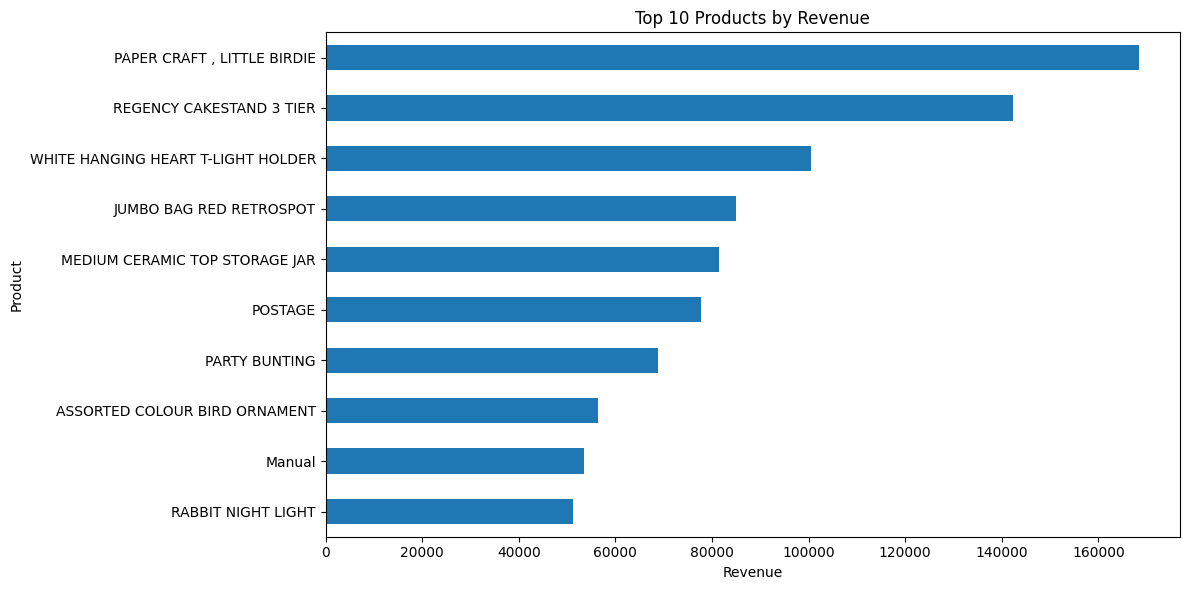

In [30]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()

plt.savefig(
    '/content/top_10_products.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [31]:
sales_by_country = (
    sales_df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_country.head(10))

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


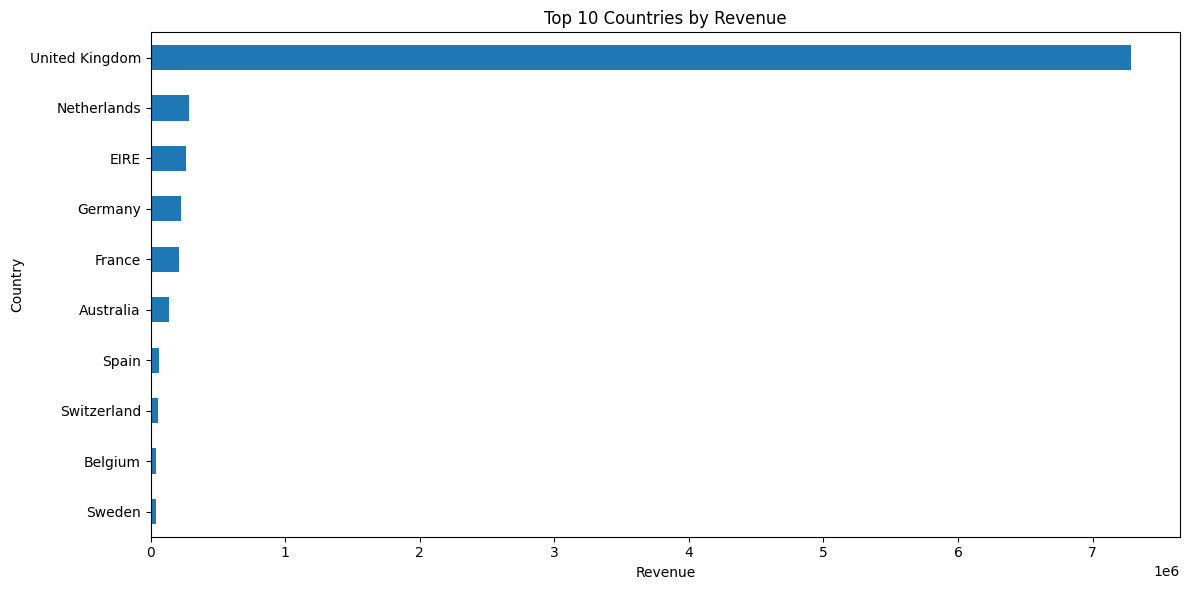

In [32]:
top_countries = sales_by_country.head(10)

plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.tight_layout()

plt.savefig(
    '/content/top_10_countries.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [33]:
sales_df['InvoiceDate'] = pd.to_datetime(
    sales_df['InvoiceDate']
)

sales_df['YearMonth'] = (
    sales_df['InvoiceDate'].dt.to_period('M')
)

monthly_sales = (
    sales_df.groupby('YearMonth')['Revenue']
    .sum()
)

print(monthly_sales)

YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64


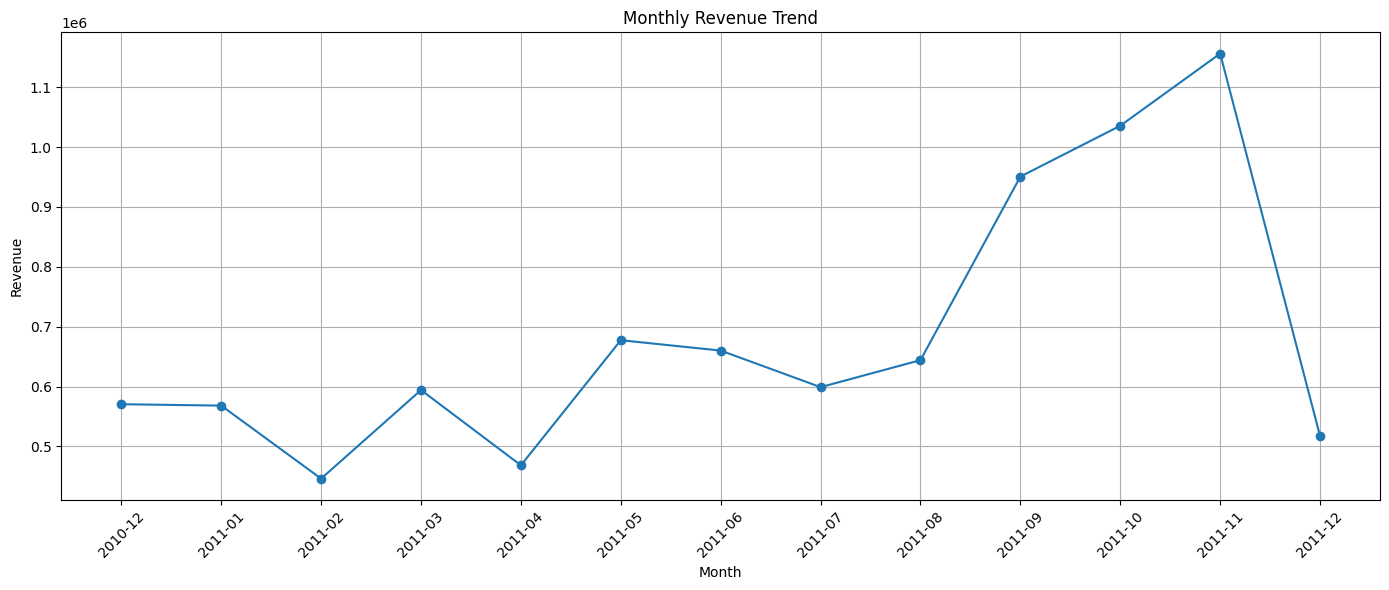

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    '/content/monthly_sales_trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [35]:
top_customers = (
    sales_df.groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


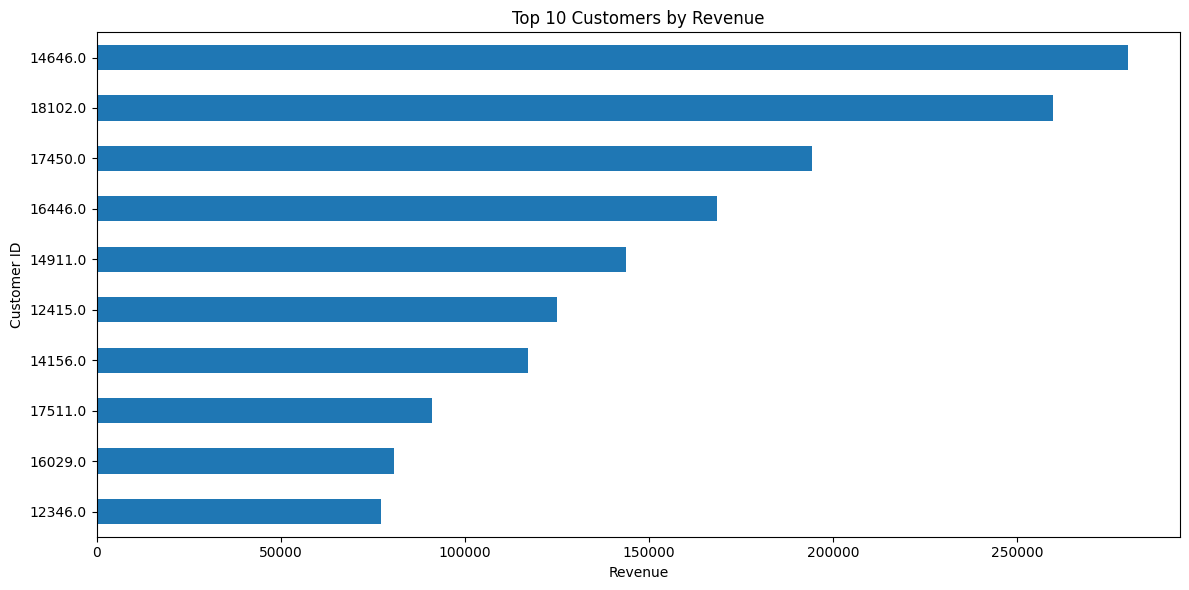

In [36]:
plt.figure(figsize=(12, 6))

top_customers.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Customer ID')
plt.tight_layout()

plt.savefig(
    '/content/top_10_customers.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [37]:
import os

output_folder = '/content/online_retail_outputs'

os.makedirs(output_folder, exist_ok=True)

top_products.to_csv(
    f'{output_folder}/top_products.csv'
)

sales_by_country.to_csv(
    f'{output_folder}/sales_by_country.csv'
)

monthly_sales.to_csv(
    f'{output_folder}/monthly_sales.csv'
)

top_customers.to_csv(
    f'{output_folder}/top_customers.csv'
)

print("All analysis tables saved successfully!")

All analysis tables saved successfully!


In [38]:
import os
import zipfile

project_folder = '/content/online_retail_outputs'
os.makedirs(project_folder, exist_ok=True)

# Copy charts into the output folder
for filename in [
    'top_10_products.png',
    'top_10_countries.png',
    'monthly_sales_trend.png',
    'top_10_customers.png'
]:
    source = f'/content/{filename}'
    if os.path.exists(source):
        import shutil
        shutil.copy(source, project_folder)

# Create a ZIP archive
zip_path = '/content/Online_Retail_Analysis_Results.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zip_file:
    for filename in os.listdir(project_folder):
        file_path = os.path.join(project_folder, filename)
        zip_file.write(file_path, arcname=filename)

print("Project results are ready!")

Project results are ready!
